<a href="https://colab.research.google.com/github/Brown-Brayden/Problem-Set-1-Econ_3916_PS1/blob/main/Problem_Set_1_Econ_3916_PS1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.

**The household:** Jordan, 27, single, works full time as a dental hygienist in Columbus, Ohio, and is the only earner (about $52,000 a year). They rent a one-bedroom apartment, drive a financed used car 20 minutes to work (no transit option on their route), and spend about $3,000 a month: 40% on rent, 21% on food (groceries and eating out), 21% on the car (payment, gas, insurance), and the rest on electricity, phone and internet, clothing, and health care.

> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [2]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.
# Prices are Jordan's monthly dollar outlay on each category, at 2019 and 2024 prices.
# Weights are each category's share of 2019 spending ($3,000 a month).
household_basket = [
    {"Item": "Rent",              "Price_2019": 1200, "Price_2024": 1524, "weight": 0.40},
    {"Item": "Groceries",         "Price_2019":  420, "Price_2024":  529, "weight": 0.14},
    {"Item": "Used car payment",  "Price_2019":  300, "Price_2024":  381, "weight": 0.10},
    {"Item": "Gasoline",          "Price_2019":  180, "Price_2024":  229, "weight": 0.06},
    {"Item": "Car insurance",     "Price_2019":  150, "Price_2024":  218, "weight": 0.05},
    {"Item": "Electricity",       "Price_2019":  120, "Price_2024":  152, "weight": 0.04},
    {"Item": "Eating out",        "Price_2019":  210, "Price_2024":  273, "weight": 0.07},
    {"Item": "Phone & internet",  "Price_2019":  150, "Price_2024":  147, "weight": 0.05},
    {"Item": "Clothing",          "Price_2019":  120, "Price_2024":  127, "weight": 0.04},
    {"Item": "Health care",       "Price_2019":  150, "Price_2024":  171, "weight": 0.05},
]

In [3]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

10 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

In [4]:
def laspeyres(basket, base_key, current_key):
    """Base-weighted price index for `basket`, with the base period = 100."""
    # Each category's price relative, weighted by its base-period spending share
    return 100 * sum(item["weight"] * item[current_key] / item[base_key] for item in basket)

In [5]:
# 1. the unweighted average price change across categories
def price_change(old, new):
    """Percentage change from old to new."""
    return (new - old) / old * 100

changes = [price_change(item["Price_2019"], item["Price_2024"]) for item in household_basket]
unweighted_change = np.mean(changes)
print(f"Unweighted average price change: {unweighted_change:.2f}%")

# 2. your weighted Laspeyres index
household_index_2024 = laspeyres(household_basket, "Price_2019", "Price_2024")
weighted_change = household_index_2024 - 100
print(f"Laspeyres index (2019 = 100):    {household_index_2024:.2f}  ->  {weighted_change:.2f}% rise")

# 3. the gap between them
gap = weighted_change - unweighted_change
print(f"Gap (weighted minus unweighted): {gap:.2f} percentage points")

pd.DataFrame(household_basket).assign(Change_pct=np.round(changes, 1))

Unweighted average price change: 22.70%
Laspeyres index (2019 = 100):    125.03  ->  25.03% rise
Gap (weighted minus unweighted): 2.33 percentage points


,Item,Price_2019,Price_2024,weight,Change_pct
0,Rent,1200,1524,0.40,27.0
1,Groceries,420,529,0.14,26.0
2,Used car payment,300,381,0.10,27.0
3,Gasoline,180,229,0.06,27.2
4,Car insurance,150,218,0.05,45.3
5,Electricity,120,152,0.04,26.7
6,Eating out,210,273,0.07,30.0
7,Phone & internet,150,147,0.05,-2.0
8,Clothing,120,127,0.04,5.8
9,Health care,150,171,0.05,14.0


**Why do the two differ, and which would you defend to the client?**

The weighted Laspeyres index puts Jordan's cost of living up **25.0%** from 2019 to 2024. The unweighted average of the ten category changes is **22.7%**, so the gap is about **2.3 percentage points**.

They differ because the unweighted average gives every category the same vote. Clothing (4% of the budget, +5.8%) counts as much as rent (40%, +27%), and so does phone and internet (5%, −2%). The categories that barely rose are small parts of Jordan's spending, while the big ones (rent, groceries, the car) rose 25–30%. Averaging without weights lets the minor items pull the figure down.

I would defend the **weighted index** to the client. It answers the question the client actually has: how much more does it cost to buy the same monthly bundle Jordan bought in 2019? A $3 cut in the phone bill cannot offset a $324 rise in rent. Its known weakness is that it holds 2019 quantities fixed and ignores substitution, such as Jordan eating out less as restaurant prices rose. So it slightly overstates the true rise in cost of living, but that bias is small next to the error from ignoring weights.

---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [6]:
import json
import time
import urllib.request
from google.colab import userdata

series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02",
              # extra proxies Jordan's car-dependent budget needs
              "CUSR0000SETB01", "CUSR0000SEFV"]

series_names = {
    "CPIAUCSL":       "All items (headline CPI)",
    "CUSR0000SEHA":   "Rent of primary residence",
    "CUSR0000SAF11":  "Food at home",
    "CUSR0000SETA02": "Used cars and trucks",
    "CUSR0000SETB01": "Gasoline",

    "CUSR0000SEFV":   "Food away from home",
}

# The FRED API key from Lab 2, read from Colab Secrets (key icon in the left sidebar,
# name FRED_API_KEY, Notebook access ON). It never appears in this notebook.
try:
    FRED_API_KEY = userdata.get("FRED_API_KEY")
except Exception:
    FRED_API_KEY = None

fred_cache = {}   # series already downloaded this session, so re-running a cell does not ask FRED again

def fetch_fred(series_id, retries=3):
    """Return one FRED series as a date-indexed Series.

    Uses the FRED API when FRED_API_KEY is in Colab Secrets (the reliable route),
    otherwise the public CSV link from Lab 2. Waits and retries if FRED is slow.
    """
    if series_id in fred_cache:
        return fred_cache[series_id]
    if FRED_API_KEY:
        url = (f"https://api.stlouisfed.org/fred/series/observations?"
               f"series_id={series_id}&api_key={FRED_API_KEY}&file_type=json")
    else:
        url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"

    for attempt in range(retries):
        try:
            if FRED_API_KEY:
                with urllib.request.urlopen(url, timeout=30) as response:
                    payload = json.load(response)
                frame = pd.DataFrame(payload["observations"])[["date", "value"]]
            else:
                frame = pd.read_csv(url)
            break
        except Exception as err:
            if attempt == retries - 1:
                raise ConnectionError(f"{series_id}: FRED did not respond after {retries} tries. "
                                      f"Last error: {type(err).__name__}: {err}") from None
            wait = 5 * 2 ** attempt               # 5 s, then 10 s
            print(f"{series_id}: {type(err).__name__}, retrying in {wait}s")
            time.sleep(wait)

    frame.columns = ["date", series_id]
    frame["date"] = pd.to_datetime(frame["date"])
    frame[series_id] = pd.to_numeric(frame[series_id], errors="coerce")   # "." becomes NaN
    series = frame.set_index("date")[series_id]
    fred_cache[series_id] = series
    time.sleep(0.5)                               # pause between downloads
    return series

print("Downloading via the FRED API." if FRED_API_KEY else
      "No FRED_API_KEY in Colab Secrets: using the CSV link.")
fred = {sid: fetch_fred(sid) for sid in series_ids}
data = pd.concat(fred.values(), axis=1)
data.tail()

,CPIAUCSL,CUSR0000SEHA,CUSR0000SAF11,CUSR0000SETA02,CUSR0000SETB01,CUSR0000SEFV
date,,,,,,
2026-04-01,332.407,445.118,320.633,179.822,353.740,393.546
2026-05-01,333.979,446.729,320.836,180.005,378.660,394.728
2026-06-01,332.568,447.397,321.446,179.591,341.980,395.633
2026-07-01,332.813,448.542,321.216,180.306,332.215,396.859
2026-08-01,334.131,449.321,321.335,180.965,345.169,397.868


| Series | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|
| `CPIAUCSL` | The benchmark the client will compare against: the average urban consumer's whole basket. | Its weights (about a third shelter, small vehicle share) are not Jordan's; it averages over homeowners, transit users and families. |
| `CUSR0000SEHA` | Tracks rents actually paid by tenants, which is Jordan's largest line (40%). | It is a national average of *all* tenants, mostly sitting tenants whose rent rises slowly; it lags new-lease prices and says nothing about Columbus specifically. |
| `CUSR0000SAF11` | Prices of food bought at stores, matching the groceries line. | Fixed-quality items; misses Jordan switching to store brands or cheaper stores, and regional grocery price differences. |
| `CUSR0000SETA02` | Used-vehicle prices drive the size of Jordan's car loan. | Jordan pays a monthly loan, not the sticker price; it misses interest-rate increases on auto loans, which raised payments beyond the price change. |
| `CUSR0000SETB01` | Gasoline is a direct cost of a car commute. | National pump price; Ohio's gas taxes and prices differ, and it ignores how many miles Jordan drives. |
| `CUSR0000SEFV` | Restaurant and takeout prices, matching eating out. | Mix of meal types; misses tipping norms and delivery fees on apps. |

### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

In [7]:
# Rebase to 2019 = 100
# Divide each series by its own 2019 annual average, so 2019 = 100 for all of them,
# matching the household basket's base period.
rebased = data.apply(lambda s: s / s.loc["2019"].mean() * 100)

# 2024 annual average of each rebased series, for comparison with the household index
rebased_2024 = rebased.loc["2024"].mean().rename(series_names).round(1)
print(f"Household Laspeyres index, 2024: {household_index_2024:.1f}")
rebased_2024

Household Laspeyres index, 2024: 125.0


,0
All items (headline CPI),122.7
Rent of primary residence,126.9
Food at home,126.8
Used cars and trucks,128.7
Gasoline,127.6
Food away from home,129.7


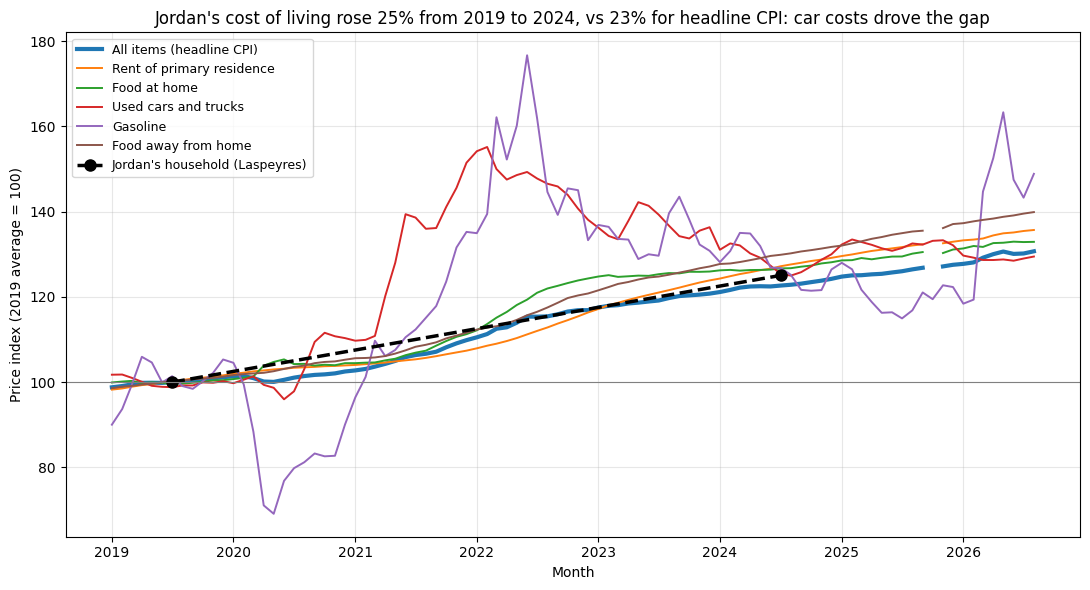

In [8]:
# One chart: every rebased series, plus your household index
cpi_2024 = rebased_2024[series_names["CPIAUCSL"]]

fig, ax = plt.subplots(figsize=(11, 6))
for sid in series_ids:
    width = 3 if sid == "CPIAUCSL" else 1.4
    ax.plot(rebased.loc["2019":, sid], lw=width, label=series_names[sid])

# The household index is only known at the two basket dates (annual averages, plotted mid-year)
hh_dates = pd.to_datetime(["2019-07-01", "2024-07-01"])
ax.plot(hh_dates, [100, household_index_2024], "k--o", lw=2.5, ms=8,
        label="Jordan's household (Laspeyres)")

ax.axhline(100, color="grey", lw=0.8)
ax.set_xlabel("Month")
ax.set_ylabel("Price index (2019 average = 100)")
ax.set_title(f"Jordan's cost of living rose {household_index_2024 - 100:.0f}% from 2019 to 2024, "
             f"vs {cpi_2024 - 100:.0f}% for headline CPI: car costs drove the gap")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet — a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. Report the count whatever it
> is; if it is not zero, list the missing months.

In [9]:
# First observation, last observation, frequency and missing months, for every series
audit_rows = []
for sid, s in fred.items():
    observed = s.dropna()                      # FRED marks unpublished months with "."
    grid = observed.asfreq("MS")               # one row per month, gaps become NaN
    missing = grid[grid.isna()].index.strftime("%Y-%m").tolist()
    freq = pd.infer_freq(observed.index[:36])
    audit_rows.append({
        "Series": sid,
        "First": observed.index.min().strftime("%Y-%m"),
        "Last": observed.index.max().strftime("%Y-%m"),
        "Frequency": "Monthly" if freq == "MS" else freq,
        "Missing months": len(missing),
        "Which": ", ".join(missing) if missing else "none",
    })

audit = pd.DataFrame(audit_rows).set_index("Series")
audit

,First,Last,Frequency,Missing months,Which
Series,,,,,
CPIAUCSL,1947-01,2026-08,Monthly,1,2025-10
CUSR0000SEHA,1981-01,2026-08,Monthly,1,2025-10
CUSR0000SAF11,1952-01,2026-08,Monthly,1,2025-10
CUSR0000SETA02,1953-01,2026-08,Monthly,0,none
CUSR0000SETB01,1967-01,2026-08,Monthly,0,none
CUSR0000SEFV,1953-01,2026-08,Monthly,1,2025-10


| Series | First | Last | Frequency | Missing months |
|---|---|---|---|---|
| `CPIAUCSL` | 1947-01 | 2026-08 | Monthly | 1 (2025-10) |
| `CUSR0000SEHA` | 1981-01 | 2026-08 | Monthly | 1 (2025-10) |
| `CUSR0000SAF11` | 1952-01 | 2026-08 | Monthly | 1 (2025-10) |
| `CUSR0000SETA02` | 1953-01 | 2026-08 | Monthly | 0 |
| `CUSR0000SETB01` | 1967-01 | 2026-08 | Monthly | 0 |
| `CUSR0000SEFV` | 1953-01 | 2026-08 | Monthly | 1 (2025-10) |

Four of the six series are missing **October 2025**. BLS did not publish October 2025 CPI because the federal government shutdown stopped its price collection that month. Used cars and gasoline have no gap, most likely because BLS builds those two indexes largely from secondary data sources rather than its own in-person price collection, so it could still compute them. The gap matters for any month-to-month change that spans October 2025. It does not affect the 2019 and 2024 annual averages this brief relies on.

### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [10]:
# Start dates side by side, and the common sample
starts = pd.Series({sid: s.dropna().index.min() for sid, s in fred.items()}).sort_values()
ends = pd.Series({sid: s.dropna().index.max() for sid, s in fred.items()})
print(starts.dt.strftime("%Y-%m").to_string())

common_start, common_end = starts.max(), ends.min()
longest = starts.idxmin()
common_months = len(pd.date_range(common_start, common_end, freq="MS"))
longest_months = len(pd.date_range(starts[longest], ends[longest], freq="MS"))
discarded = longest_months - common_months

print(f"\nCommon sample starts:     {common_start:%Y-%m} (set by {starts.idxmax()})")
print(f"Common sample length:     {common_months} months ({common_start:%Y-%m} to {common_end:%Y-%m})")
print(f"Months of {longest} discarded: {discarded} of {longest_months}")

CPIAUCSL          1947-01
CUSR0000SAF11     1952-01
CUSR0000SETA02    1953-01
CUSR0000SEFV      1953-01
CUSR0000SETB01    1967-01
CUSR0000SEHA      1981-01

Common sample starts:     1981-01 (set by CUSR0000SEHA)
Common sample length:     548 months (1981-01 to 2026-08)
Months of CPIAUCSL discarded: 408 of 956


In [11]:
# Headline comparison: full history vs common sample
# Headline = each series' average annual inflation rate, and its gap over headline CPI.
def annualized_inflation(s):
    """Compound annual % change from the first to the last observation."""
    s = s.dropna()
    months = (s.index[-1].year - s.index[0].year) * 12 + (s.index[-1].month - s.index[0].month)
    return ((s.iloc[-1] / s.iloc[0]) ** (12 / months) - 1) * 100

full = pd.Series({sid: annualized_inflation(s) for sid, s in fred.items()})
common = pd.Series({sid: annualized_inflation(s.loc[common_start:common_end]) for sid, s in fred.items()})

headline = pd.DataFrame({
    "Full history, % per yr": full,
    "Gap vs CPI (full)": full - full["CPIAUCSL"],
    "Common sample, % per yr": common,
    "Gap vs CPI (common)": common - common["CPIAUCSL"],
}).rename(index=series_names).round(2)
headline

,"Full history, % per yr",Gap vs CPI (full),"Common sample, % per yr",Gap vs CPI (common)
All items (headline CPI),3.51,0.00,2.99,0.00
Rent of primary residence,3.73,0.22,3.73,0.74
Food at home,3.18,-0.33,2.75,-0.24
Used cars and trucks,2.53,-0.97,2.10,-0.89
Gasoline,4.42,0.91,2.68,-0.32
Food away from home,4.05,0.54,3.37,0.38


**What restricting to the common sample assumes, and what not restricting assumes:**

**The sample:** the common sample starts in **January 1981**, set by the rent series (`CUSR0000SEHA`), and runs **548 months** to August 2026. It discards **408 of the 956 months** of headline CPI, the longest series.

**Restricting to the common sample** assumes that comparing categories only makes sense over the *same* window, and that this window is representative enough to stand for "the long run." It throws away 408 months of the longest series, including whatever inflation episodes happened before January 1981, such as the 1970s oil shocks. If those episodes hit the categories unevenly, the common-sample gap describes a recent era, not history.

**Not restricting** assumes that averages taken over *different* windows are comparable. That is usually false: a series that starts earlier carries extra decades of inflation, and in a high-inflation era that pushes its average up for reasons unrelated to its category. The gap vs CPI then mixes "this category inflates faster" with "this series covers different years."

For this brief I use the common sample. The client's question compares categories against one another, so holding the period fixed is the honest choice. The change between the two columns above shows how much the full-history numbers would have misled. The rent-vs-CPI gap grows from +0.22 to +0.74 points a year, because CPI's full history includes the high-inflation 1970s while rent's does not. Gasoline flips from +0.91 above CPI to −0.32 below it, because its full history starts in 1967 and includes both oil shocks.

### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

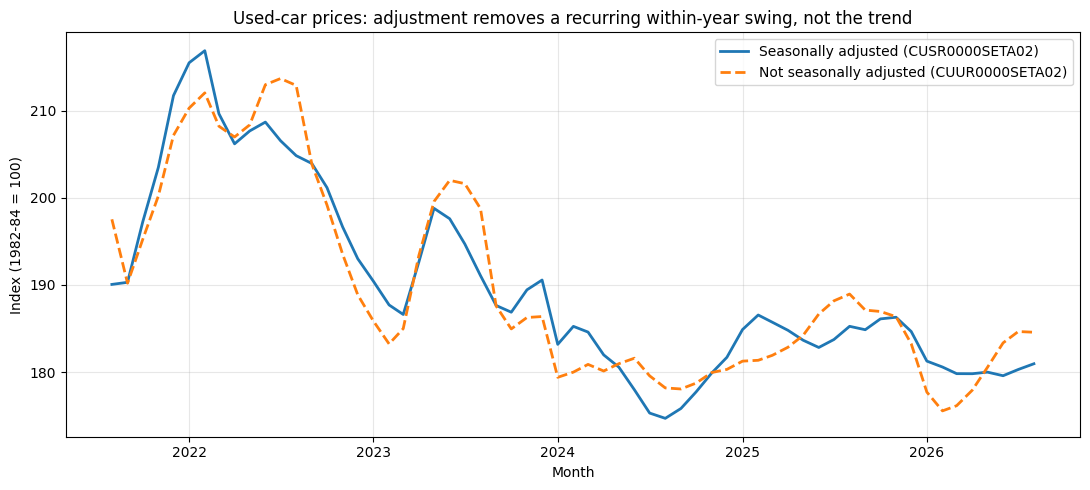

,Mean NSA/SA by month
date,
1,0.9784
2,0.9740
3,0.9847
4,0.9953
5,1.0031
6,1.0211
7,1.0285
8,1.0298
9,1.0047


In [12]:
# Seasonally adjusted vs unadjusted, last five years
# Used cars: prices have a visible summer peak (July-August) and a winter low, so the gap is easy to see.
sa = fred["CUSR0000SETA02"].dropna()
nsa = fetch_fred("CUUR0000SETA02").dropna()

window_start = sa.index.max() - pd.DateOffset(years=5)
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(sa.loc[window_start:], lw=2, label="Seasonally adjusted (CUSR0000SETA02)")
ax.plot(nsa.loc[window_start:], lw=2, ls="--", label="Not seasonally adjusted (CUUR0000SETA02)")
ax.set_xlabel("Month")
ax.set_ylabel("Index (1982-84 = 100)")
ax.set_title("Used-car prices: adjustment removes a recurring within-year swing, not the trend")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Implied seasonal factor: NSA / SA, averaged by calendar month
factor = (nsa / sa).loc[window_start:].dropna()
factor.groupby(factor.index.month).mean().round(4).rename("Mean NSA/SA by month")

**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

**What the gap consists of:** BLS's estimate of the predictable calendar pattern in used-car prices, and nothing else. BLS fits seasonal factors with X-13ARIMA-SEATS and divides them out of the raw (NSA) series. The NSA/SA ratio above is that factor. It is above 1 from May through September, when prices are seasonally high, peaking in July and August at about 1.03. It is below 1 in the slow months, lowest in January and February at about 0.97. Someone decided which pattern counts as "seasonal." BLS also re-estimates the factors every February and revises the last five years of the SA series, so the SA numbers we downloaded are not the numbers published at the time. The NSA series is never revised.

**Which belongs in this brief:** the **seasonally adjusted** series. The chart and the audit read month-to-month movements, and an unadjusted series would show a summer "price spike" that happens every year and tells the client nothing new. For the headline 2019-vs-2024 comparison the choice barely matters, because annual averages cancel the seasonal pattern; I rebase on 2019 *annual averages* for exactly that reason. If the client wanted to index a contract (say, a wage escalator) to these numbers, I would switch to NSA, since it is final when published.

---
## Phase 4: AI Expansion (25 pts)


### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

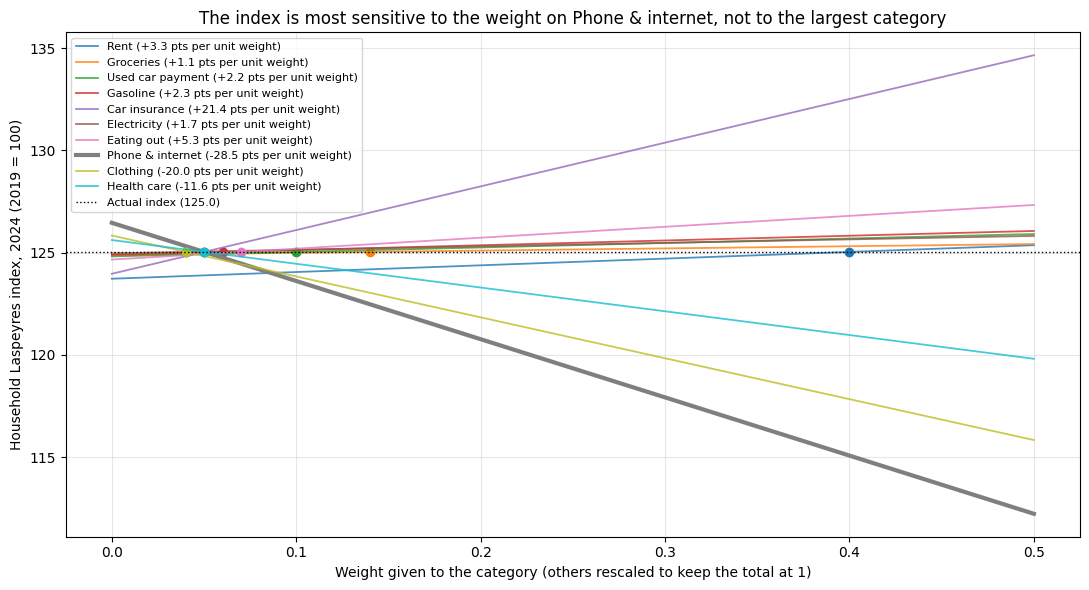

,Index pts per unit weight
Phone & internet,-28.46
Car insurance,21.37
Clothing,-20.00
Health care,-11.61
Eating out,5.34
Rent,3.28
Gasoline,2.33
Used car payment,2.19
Electricity,1.70
Groceries,1.07


In [13]:
# Paste the AI's code here, run it, and correct it where it is wrong
# (Code below is the model's reply, unchanged. It reuses laspeyres() and household_basket from Phase 1.)

def reweighted_basket(basket, item_name, new_weight):
    """Copy of `basket` with `item_name`'s weight set to `new_weight` and every
    other weight rescaled by the same factor, so the weights still sum to 1."""
    # Why renormalise: a Laspeyres index is a weighted AVERAGE of price relatives,
    # so the weights must sum to 1. If we raised one weight and left the others alone,
    # the weights would sum to more than 1 and the index would rise mechanically:
    # we would be measuring a bigger basket, not a different mix. Scaling the others
    # in proportion keeps their relative shares fixed, so the only thing that changes
    # is how much of the budget goes to the swept category.
    old_weight = next(item["weight"] for item in basket if item["Item"] == item_name)
    scale = (1 - new_weight) / (1 - old_weight)
    return [
        {**item, "weight": new_weight if item["Item"] == item_name else item["weight"] * scale}
        for item in basket
    ]

weight_grid = np.linspace(0, 0.5, 51)

sweep = pd.DataFrame(
    {
        item["Item"]: [
            laspeyres(reweighted_basket(household_basket, item["Item"], w), "Price_2019", "Price_2024")
            for w in weight_grid
        ]
        for item in household_basket
    },
    index=weight_grid,
)
sweep.index.name = "weight"

# The index is linear in any one weight, so sensitivity is a single number per category:
# index points gained per unit of weight shifted to it. Rank by absolute size.
sensitivity = ((sweep.iloc[-1] - sweep.iloc[0]) / (weight_grid[-1] - weight_grid[0]))
sensitivity = sensitivity.sort_values(key=np.abs, ascending=False)
most_sensitive = sensitivity.index[0]

# What high sensitivity to one category would mean: the headline number would depend
# mostly on how well we measured that ONE weight, so an error in the household's
# spending share for it would pass almost one-for-one into the result we report.
# That category is where the brief needs its best evidence, or a stated range.

fig, ax = plt.subplots(figsize=(11, 6))
for name in sweep.columns:
    is_top = name == most_sensitive
    line, = ax.plot(sweep.index, sweep[name], lw=3 if is_top else 1.3,
                    alpha=1 if is_top else 0.8, label=f"{name} ({sensitivity[name]:+.1f} pts per unit weight)")
    actual_w = next(i["weight"] for i in household_basket if i["Item"] == name)
    ax.plot(actual_w, household_index_2024, "o", color=line.get_color(), ms=6)

ax.axhline(household_index_2024, color="black", ls=":", lw=1, label=f"Actual index ({household_index_2024:.1f})")
ax.set_xlabel("Weight given to the category (others rescaled to keep the total at 1)")
ax.set_ylabel("Household Laspeyres index, 2024 (2019 = 100)")
ax.set_title(f"The index is most sensitive to the weight on {most_sensitive}, "
             f"not to the largest category")
ax.legend(fontsize=8, loc="best")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

sensitivity.round(2).rename("Index pts per unit weight")

In [14]:
# My checks on the model's code
# Check 1: at each category's actual weight, the reweighted basket must reproduce the Phase 1 index
for item in household_basket:
    at_actual = laspeyres(reweighted_basket(household_basket, item["Item"], item["weight"]),
                          "Price_2019", "Price_2024")
    assert np.isclose(at_actual, household_index_2024), item["Item"]

# Check 2: weights still sum to 1 at the ends of the sweep
for item in household_basket:
    for w in (0.0, 0.5):
        total = sum(i["weight"] for i in reweighted_basket(household_basket, item["Item"], w))
        assert np.isclose(total, 1.0), (item["Item"], w)

# Check 3: the slope has a closed form, 100 * (r_k - R_others), where r_k is the category's
# price relative and R_others is the weighted average relative of everything else
relatives = {i["Item"]: i["Price_2024"] / i["Price_2019"] for i in household_basket}
analytic = {}
for i in household_basket:
    r_others = (household_index_2024 / 100 - i["weight"] * relatives[i["Item"]]) / (1 - i["weight"])
    analytic[i["Item"]] = 100 * (relatives[i["Item"]] - r_others)

check = pd.DataFrame({"Model's sweep": sensitivity, "Closed form": pd.Series(analytic)})
assert np.allclose(check["Model's sweep"], check["Closed form"])

# Check 4: contribution to the rise is a different question from sensitivity
check["Contribution to rise (pts)"] = pd.Series(
    {i["Item"]: 100 * i["weight"] * (relatives[i["Item"]] - 1) for i in household_basket})
# Realistic error band: index change if a weight were mismeasured by 5 percentage points
check["Effect of ±0.05 weight error (pts)"] = (0.05 * check["Model's sweep"]).abs()
print(f"{len(household_basket)} categories handled; all checks passed.")
check.round(2)

10 categories handled; all checks passed.


,Model's sweep,Closed form,Contribution to rise (pts),Effect of ±0.05 weight error (pts)
Car insurance,21.37,21.37,2.27,1.07
Clothing,-20.00,-20.00,0.23,1.00
Eating out,5.34,5.34,2.10,0.27
Electricity,1.70,1.70,1.07,0.09
Gasoline,2.33,2.33,1.63,0.12
Groceries,1.07,1.07,3.63,0.05
Health care,-11.61,-11.61,0.70,0.58
Phone & internet,-28.46,-28.46,-0.10,1.42
Rent,3.28,3.28,10.80,0.16
Used car payment,2.19,2.19,2.70,0.11


**What did the model get wrong, or get right in a way you had to check? Show the check.**

**What it got right, and how I checked it.** The code ran without changes, and the checks in the cell above pass:
1. *Reproduces Phase 1.* Setting any category to its actual weight gives back 125.03, so `reweighted_basket` rescales without distorting the basket.
2. *Weights stay at 1.* At both ends of every sweep the weights sum to 1.0, which is what the renormalisation comment claims.
3. *Slopes match theory.* With one weight swept, the index is linear: slope = 100 × (category's price relative − weighted average relative of the others). The closed-form slopes match the model's sweep exactly. Phone & internet is about −28.5 points per unit of weight, car insurance +21.4, clothing −20.0, and rent only +3.3.

**What I had to correct or qualify.**
- *Category count.* My prompt said "six categories" but my basket has ten. The model didn't hard-code six. I confirmed the code handles all ten instead of trusting that it would.
- *The 0 to 0.5 range is extrapolation for small categories.* Giving clothing (actual weight 0.04) a 50% budget share is not a plausible household. Ranking by slope is still valid because the index is linear, but the honest uncertainty is a realistic weight error. With ±0.05, the largest effect is about ±1.4 points, from phone & internet. I added that column.
- *"Dominates" means two different things.* The model ranks sensitivity. But **rent** contributes the most to the rise (10.8 of the 25 points, 43%), while the result is *least* sensitive to rent's weight, because rent rose at almost the same rate as everything else. The brief has to keep "what drove the increase" separate from "what the number is fragile to."
- *Edge case.* `reweighted_basket` divides by `1 - old_weight`, so it would crash if one category held the entire budget. That doesn't apply to this basket, but it's worth knowing.

### AI Transcript

**Model:** Claude Opus 5.5 (Anthropic), via Claude Code &nbsp; **Date:** October 9, 2026

*Paste the prompt exactly as you sent it, then the model's reply exactly as it
came back, before your corrections.*

**Prompt**

> [Prep] Act as an applied economist who builds reproducible analysis for client deliverables.
> [Request] I have a household price index built as a weighted Laspeyres over six spending categories, in a list of dicts named household_basket with keys Item, Price_2019, Price_2024 and weight. Write Python that sweeps each category’s weight from 0 to 0.5, holding the others in proportion, recomputes the index, and produces a single chart showing which category’s weight the result is most sensitive to.
> [Iterate] numpy, pandas and matplotlib only. Reuse my variable names. No deprecated matplotlib arguments.
> [Mechanism Check] Add comments explaining why renormalising the other weights is necessary, and what it would mean if the index were highly sensitive to a single category.
> [Evaluate] Tell me which category dominates my result and what I should say to a client about it.

**Reply**

The code is in the Phase 4.1 code cell above, unchanged from the reply. It defines `reweighted_basket()`, builds `sweep` (index value at 51 weights from 0 to 0.5 for each category), computes `sensitivity` (index points per unit of weight) and draws one chart with a line per category. It reuses your `laspeyres()` and `household_basket`. It doesn't assume six categories: your basket has ten, and the code loops over whatever is there.

*Why the index is linear in each weight:* with weight w on category k and the rest rescaled by (1 − w)/(1 − w_k), the index is 100 × [w·r_k + (1 − w)·R_others], where r_k is k's price relative and R_others is the weighted average relative of the other categories. The slope is 100 × (r_k − R_others). So sensitivity depends on how far a category's price change is from everything else, **not on how big the category is.**

*Evaluate.* With your basket (index 125.0):
- **Most sensitive: Phone & internet**, about −28 points per unit of weight, because its price fell 2% while the rest of the basket rose about 26%. Then car insurance (+21, up 45%), clothing (−20, up 6%) and health care (−12, up 14%).
- **Least sensitive: rent** (about +3), even though it is 40% of spending. Rent rose 27%, almost exactly as fast as the rest of the basket, so moving weight onto or off it barely changes the answer.
- **Rent still contributes the most to the increase:** 0.40 × 27% ≈ 10.8 of the 25 points.

*What to tell the client:* "Your costs rose about 25%. Rent is the biggest single reason, but the figure doesn't depend on getting rent's share exactly right. The estimate is most exposed to how much you spend on phone/internet and car insurance, the two items whose prices moved very differently from everything else. If either share is off by five points of your budget, the headline moves by about 1 to 1.5 points, so read it as roughly 24–26%." A sweep to 0.5 is a stress test, not a realistic scenario for small categories. Report the realistic band (±0.05 on a weight) alongside the chart.

### Task 4.2: The written finding (10 pts)

250 words at most, to the director. A number in the first sentence, no code,
and a confidence level.

Jordan's household costs rose **25.0%** from 2019 to 2024, about two points more than headline CPI (roughly 23%). On a $3,000 monthly budget, that is about $750 more each month to buy the same things.

The gap with CPI comes from the car. Jordan has no transit option and spends 21% of the budget on driving. Car insurance premiums rose about 45%, and the car payment and gasoline about 27% each. Rent is the largest single driver of the increase, at 43% of it. But rent rose at about the same pace as everything else, so it does not explain why Jordan fared worse than the average consumer.

The result does not hinge on rent's share: moving rent anywhere from 0% to 50% of the budget changes the index by less than two points. It is most exposed to the share spent on phone and internet, whose prices fell, and on car insurance. A five-point error in either share moves the headline by about one to one and a half points.

**Confidence: moderate.** Under any realistic error in the weights, Jordan's costs still outpace CPI. The exact size is less certain, for two reasons: the official series are national averages, not Columbus prices, and the household's 2024 prices are estimates. I would report the increase as **24% to 26.5%**, with 25% as the central figure.

---
### Before you submit
- [ ] Every step above has output, and every explanation is in a text cell
- [ ] The AI Transcript names the model and the date
- [ ] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1/` on GitHub